# Mapa de escenarios 2027 (GeoJSON)

**Objetivo.** Generar un archivo **GeoJSON** con los municipios de México, donde cada municipio trae los resultados de `escenarios_2027.csv` (abstención y semáforo sin intervención y con intervención de 1 a 5 puntos). Es el archivo de mapa que pide la convocatoria y también la fuente del tablero.

**Datos.**
- `Datos/datos_procesados/modelo/escenarios_2027.csv` (resultados por municipio) y su diccionario (`Datos/datos_procesados/modelo/diccionario.txt`).
- `Datos/mapa/mg_2025_integrado.zip`: Marco Geoestadístico Integrado 2025 de INEGI (2,478 municipios). Solo se usa para dibujar los límites; no entra al modelo.

**Qué se hace, en orden.**
1. Se extraen del zip solo las capas de municipios y estados.
2. Se cruzan los municipios de INEGI con los nuestros. Nuestra base no tiene clave de INEGI, así que el cruce es por **nombre de estado y municipio** (sin acentos ni mayúsculas) y 14 casos se resuelven a mano.
3. Se pegan los resultados de los escenarios a cada polígono.
4. Se simplifican los polígonos y se cambian las coordenadas a latitud y longitud.
5. Se guarda el GeoJSON y su diccionario en `Entregables/mapa_escenarios/`.

**Casos especiales (decididos con la usuaria).**
- San Juan Mixtepec y San Pedro Mixtepec (Oaxaca): INEGI tiene dos municipios con cada nombre y nuestra base solo una fila; los dos polígonos reciben el mismo dato y se marcan con `AGRUPADO = Sí`.
- Villa de Pozos (San Luis Potosí): es un municipio nuevo que no está en nuestra base; queda sin datos (`EN_BASE = No`).

## 1. Configuración
Se definen las rutas, el tamaño de simplificación de los polígonos (en metros) y las equivalencias de nombres que no cruzan solas.

- `NOMBRE_ESTADO`: tres estados que en nuestra base tienen el nombre corto.
- `EQUIVALENCIAS`: municipios cuyo nombre en nuestra base es distinto al de INEGI. Cada uno apunta a la clave (o claves) de INEGI.

In [1]:
from pathlib import Path
import json
import re
import unicodedata
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapefile
import shapely
import pyproj

warnings.filterwarnings("ignore")

_cwd = Path.cwd().resolve()
RAIZ = next(p for p in [_cwd, *_cwd.parents] if (p / "Datos").is_dir())
RUTA_ZIP = RAIZ / "Datos" / "mapa" / "mg_2025_integrado.zip"
CARPETA_CAPAS = RAIZ / "Datos" / "mapa" / "capas"
RUTA_ESCENARIOS = RAIZ / "Datos" / "datos_procesados" / "modelo" / "escenarios_2027.csv"
RUTA_DICCIONARIO = RAIZ / "Datos" / "datos_procesados" / "modelo" / "diccionario.txt"
CARPETA_SALIDA = RAIZ / "Entregables" / "mapa_escenarios"
RUTA_GEOJSON = CARPETA_SALIDA / "mapa_escenarios_2027.geojson"
RUTA_DICCIONARIO_MAPA = CARPETA_SALIDA / "diccionario_mapa_2027.csv"

TOLERANCIA_M = 500

NOMBRE_ESTADO = {"COAHUILA": "COAHUILA DE ZARAGOZA",
                 "MICHOACAN": "MICHOACAN DE OCAMPO",
                 "VERACRUZ": "VERACRUZ DE IGNACIO DE LA LLAVE"}

EQUIVALENCIAS = {("CHIAPAS", "CINTALAPA"): ["07017"],
                 ("CHIHUAHUA", "ROSARIO"): ["08056"],
                 ("DURANGO", "SIMON BOLIVAR"): ["10006"],
                 ("GUANAJUATO", "SAN JOSE ITURBIDE"): ["11032"],
                 ("GUERRERO", "APAXTLA"): ["12006"],
                 ("MORELOS", "JONACATEPEC"): ["17013"],
                 ("OAXACA", "SAN MARTIN DE LOS CANSECOS"): ["20238"],
                 ("OAXACA", "SANTIAGO CHAZUMBA"): ["20459"],
                 ("QUINTANA ROO", "SOLIDARIDAD"): ["23008"],
                 ("SAN LUIS POTOSI", "AHUALULCO"): ["24001"],
                 ("TLAXCALA", "ZITLALTEPEC DE TRINIDAD SANCHEZ SANTOS"): ["29037"],
                 ("VERACRUZ", "COSAMALOAPAN"): ["30045"],
                 ("OAXACA", "SAN JUAN MIXTEPEC"): ["20208", "20209"],
                 ("OAXACA", "SAN PEDRO MIXTEPEC"): ["20318", "20319"]}

print("Zip de INEGI encontrado:", RUTA_ZIP.exists())

Zip de INEGI encontrado: True


## 2. Extraer las capas de municipios y estados
El zip trae muchas capas (localidades, AGEB, manzanas…) que no se necesitan. Solo se sacan `00mun` (municipios) y `00ent` (estados). Cada capa son varios archivos con el mismo nombre (`.shp` dibuja, `.dbf` trae los nombres, `.prj` dice en qué coordenadas está). Se guardan en `Datos/mapa/capas/`, que no se sube a git.

In [2]:
CARPETA_CAPAS.mkdir(exist_ok=True)
with zipfile.ZipFile(RUTA_ZIP) as z:
    for nombre in z.namelist():
        if nombre.startswith(("conjunto_de_datos/00mun.", "conjunto_de_datos/00ent.")):
            with z.open(nombre) as origen, open(CARPETA_CAPAS / Path(nombre).name, "wb") as destino:
                destino.write(origen.read())

sorted(p.name for p in CARPETA_CAPAS.iterdir())

['00ent.cpg',
 '00ent.dbf',
 '00ent.prj',
 '00ent.shp',
 '00ent.shx',
 '00mun.cpg',
 '00mun.dbf',
 '00mun.prj',
 '00mun.shp',
 '00mun.shx']

## 3. Leer las capas
Cada municipio de INEGI tiene una clave de 5 dígitos (`CVEGEO`: 2 del estado y 3 del municipio), su nombre y su polígono. Los nombres del estado vienen en otra capa, así que se pegan por la clave del estado. Los archivos están en codificación `latin-1`.

In [3]:
capa_mun = shapefile.Reader(str(CARPETA_CAPAS / "00mun"), encoding="latin-1")
capa_ent = shapefile.Reader(str(CARPETA_CAPAS / "00ent"), encoding="latin-1")

municipios = pd.DataFrame([r.as_dict() for r in capa_mun.records()])
estados = pd.DataFrame([r.as_dict() for r in capa_ent.records()]).rename(columns={"NOMGEO": "NOM_ENT"})

poligonos = [shapely.geometry.shape(s.__geo_interface__) for s in capa_mun.shapes()]
geometria_por_clave = dict(zip(municipios["CVEGEO"], poligonos))

municipios = municipios.merge(estados[["CVE_ENT", "NOM_ENT"]], on="CVE_ENT")

print(f"{len(municipios):,} municipios de INEGI")
municipios.head()

2,478 municipios de INEGI


,CVEGEO,CVE_ENT,CVE_MUN,NOMGEO,NOM_ENT
0,01001,01,001,Aguascalientes,Aguascalientes
1,01008,01,008,San José de Gracia,Aguascalientes
2,01011,01,011,San Francisco de los Romo,Aguascalientes
3,01009,01,009,Tepezalá,Aguascalientes
4,01007,01,007,Rincón de Romos,Aguascalientes


## 4. Cruzar nuestros municipios con los de INEGI
Para comparar nombres se quitan los acentos y las mayúsculas (`normalizar`): "Cintalapa de Figueroa" y "CINTALAPA DE FIGUEROA" quedan iguales. Dos municipios de INEGI repiten nombre dentro del mismo estado (los dos Mixtepec de Oaxaca), así que esos no se cruzan solos. Se prueba el cruce automático y se muestra cuántos nuestros municipios quedan sin pareja.

In [4]:
def normalizar(texto):
    sin_acentos = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(re.sub(r"[^A-Z0-9 ]", " ", sin_acentos.upper()).split())

esc = pd.read_csv(RUTA_ESCENARIOS, encoding="utf-8-sig")
esc["E"] = esc["ESTADO"].map(normalizar).replace(NOMBRE_ESTADO)
esc["M"] = esc["MUNICIPIO"].map(normalizar)
municipios["E"] = municipios["NOM_ENT"].map(normalizar)
municipios["M"] = municipios["NOMGEO"].map(normalizar)

repetidos = municipios.duplicated(["E", "M"], keep=False)
automatico = esc.merge(municipios.loc[~repetidos, ["E", "M", "CVEGEO"]], on=["E", "M"], how="left")

print(f"Cruzan solos: {automatico['CVEGEO'].notna().sum():,} de {len(esc):,}")
automatico[automatico["CVEGEO"].isna()][["ESTADO", "MUNICIPIO", "PERSONAS_2024"]]

Cruzan solos: 2,461 de 2,475


,ESTADO,MUNICIPIO,PERSONAS_2024
64,CHIAPAS,CINTALAPA,57309.0
215,CHIHUAHUA,ROSARIO,1507.0
323,DURANGO,SIMON BOLIVAR,7680.0
360,GUANAJUATO,SAN JOSE ITURBIDE,67667.0
382,GUERRERO,APAXTLA,7950.0
922,MORELOS,JONACATEPEC,12138.0
1226,OAXACA,SAN JUAN MIXTEPEC,6678.0
1255,OAXACA,SAN MARTIN DE LOS CANSECOS,724.0
1333,OAXACA,SAN PEDRO MIXTEPEC,38564.0
1473,OAXACA,SANTIAGO CHAZUMBA,3460.0


## 5. Equivalencias manuales y tabla de relación
Los 14 municipios sin pareja se resuelven con `EQUIVALENCIAS`. La tabla `relacion` tiene una fila por cada pareja (municipio nuestro, polígono de INEGI). Los dos Mixtepec aparecen dos veces cada uno (un polígono por fila) y llevan `AGRUPADO = Sí`. Se comprueba que no quede ningún municipio nuestro sin polígono ni polígono repetido.

In [5]:
cruzados = automatico[automatico["CVEGEO"].notna()][["ESTADO", "MUNICIPIO", "CVEGEO"]].assign(AGRUPADO="No")
manuales = pd.DataFrame([{"ESTADO": e, "MUNICIPIO": m, "CVEGEO": c, "AGRUPADO": "Sí" if len(claves) > 1 else "No"}
                         for (e, m), claves in EQUIVALENCIAS.items() for c in claves])
relacion = pd.concat([cruzados, manuales], ignore_index=True)

nuestros_con_poligono = relacion[["ESTADO", "MUNICIPIO"]].drop_duplicates().shape[0]
print(f"Municipios nuestros con polígono: {nuestros_con_poligono:,} de {len(esc):,}")
print("Polígonos repetidos en la relación:", relacion.duplicated("CVEGEO").sum())
print("Polígonos de INEGI sin municipio nuestro:")
municipios[~municipios["CVEGEO"].isin(relacion["CVEGEO"])][["NOM_ENT", "NOMGEO", "CVEGEO"]]

Municipios nuestros con polígono: 2,475 de 2,475
Polígonos repetidos en la relación: 0
Polígonos de INEGI sin municipio nuestro:


,NOM_ENT,NOMGEO,CVEGEO
1839,San Luis Potosí,Villa de Pozos,24059


## 6. Pegar los resultados de los escenarios a cada polígono
Se parte de los 2,478 polígonos de INEGI y se les pegan, por clave, los resultados de `escenarios_2027.csv`. Los polígonos sin municipio en nuestra base (Villa de Pozos) quedan con `EN_BASE = No` y color "Sin datos suficientes".

In [6]:
datos = (municipios[["CVEGEO", "NOM_ENT", "NOMGEO"]]
         .merge(relacion, on="CVEGEO", how="left")
         .merge(esc.drop(columns=["E", "M"]), on=["ESTADO", "MUNICIPIO"], how="left"))

datos["EN_BASE"] = datos["ESTADO"].notna().map({True: "Sí", False: "No"})
datos["AGRUPADO"] = datos["AGRUPADO"].fillna("No")
columnas_color = [c for c in datos.columns if c.startswith("SEMAFORO_")]
datos[columnas_color] = datos[columnas_color].fillna("Sin datos suficientes")

COLUMNAS = ["CVEGEO", "NOM_ENT", "NOMGEO"] + list(esc.columns.drop(["E", "M"])) + ["AGRUPADO", "EN_BASE"]
datos = datos[COLUMNAS]

print(f"{len(datos):,} polígonos | {datos['EN_BASE'].eq('Sí').sum():,} con datos de la base")
datos.head()

2,478 polígonos | 2,477 con datos de la base


,CVEGEO,NOM_ENT,NOMGEO,ESTADO,MUNICIPIO,ELECCIONES,CONFIANZA,PERSONAS_2024,PRON_SIN,SEMAFORO_SIN,...,SEMAFORO_CON_3,PERSONAS_ADIC_3,PRON_CON_4,SEMAFORO_CON_4,PERSONAS_ADIC_4,PRON_CON_5,SEMAFORO_CON_5,PERSONAS_ADIC_5,AGRUPADO,EN_BASE
0,01001,Aguascalientes,Aguascalientes,AGUASCALIENTES,AGUASCALIENTES,6.0,Alta,712266.0,0.5516,Rojo,...,Amarillo,21368.0,0.5116,Amarillo,28491.0,0.5016,Amarillo,35613.0,No,Sí
1,01008,Aguascalientes,San José de Gracia,AGUASCALIENTES,SAN JOSE DE GRACIA,6.0,Alta,6808.0,0.3627,Verde,...,Verde,204.0,0.3227,Verde,272.0,0.3127,Verde,340.0,No,Sí
2,01011,Aguascalientes,San Francisco de los Romo,AGUASCALIENTES,SAN FRANCISCO DE LOS ROMO,6.0,Alta,43732.0,0.5451,Rojo,...,Amarillo,1312.0,0.5051,Amarillo,1749.0,0.4951,Amarillo,2187.0,No,Sí
3,01009,Aguascalientes,Tepezalá,AGUASCALIENTES,TEPEZALA,6.0,Alta,17460.0,0.4201,Verde,...,Verde,524.0,0.3801,Verde,698.0,0.3701,Verde,873.0,No,Sí
4,01007,Aguascalientes,Rincón de Romos,AGUASCALIENTES,RINCON DE ROMOS,6.0,Alta,40247.0,0.5479,Rojo,...,Amarillo,1207.0,0.5079,Amarillo,1610.0,0.4979,Amarillo,2012.0,No,Sí


## 7. Simplificar los polígonos y pasar a latitud y longitud
- **Simplificar:** los polígonos de INEGI tienen mucho detalle (61 MB solo la capa de municipios). Para un mapa de todo el país basta menos. `coverage_simplify` simplifica todos juntos y respeta las fronteras compartidas, para que no queden huecos entre municipios vecinos. La tolerancia (`TOLERANCIA_M`) es en metros.
- **Coordenadas:** INEGI usa metros en una proyección cónica; el GeoJSON usa latitud y longitud. `pyproj` hace el cambio leyendo el archivo `.prj`.

In [7]:
sistema_inegi = pyproj.CRS.from_wkt((CARPETA_CAPAS / "00mun.prj").read_text())
cambio = pyproj.Transformer.from_crs(sistema_inegi, "EPSG:4326", always_xy=True)

originales = [geometria_por_clave[c] for c in datos["CVEGEO"]]
simples = shapely.coverage_simplify(originales, TOLERANCIA_M)
geometrias = shapely.transform(simples, lambda xy: np.column_stack(cambio.transform(xy[:, 0], xy[:, 1])))

print("Vértices antes:", sum(shapely.get_num_coordinates(g) for g in originales))
print("Vértices después:", sum(shapely.get_num_coordinates(g) for g in geometrias))
print("Geometrías válidas:", all(shapely.is_valid(g) for g in geometrias))

Vértices antes: 3819020
Vértices después: 273352
Geometrías válidas: True


## 8. Guardar el GeoJSON y su diccionario
Cada municipio es un `Feature` con su polígono y todas las columnas como propiedades. Las coordenadas se redondean a 5 decimales (aprox. 1 metro). El diccionario es el de los escenarios más las columnas que agrega este notebook.

In [1]:
propiedades = json.loads(datos.to_json(orient="records", double_precision=6, force_ascii=False))
features = [{"type": "Feature", "properties": p, "geometry": json.loads(shapely.to_geojson(g), parse_float=lambda x: round(float(x), 5))}
            for g, p in zip(geometrias, propiedades)]

CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
with open(RUTA_GEOJSON, "w", encoding="utf-8") as f:
    json.dump({"type": "FeatureCollection", "features": features}, f, ensure_ascii=False)

nuevas = pd.DataFrame({"COLUMNA": ["CVEGEO", "NOM_ENT", "NOMGEO", "AGRUPADO", "EN_BASE"],
                       "DESCRIPCION": ["Clave de INEGI del municipio (2 dígitos de estado y 3 de municipio).",
                                       "Nombre del estado según INEGI.",
                                       "Nombre del municipio según INEGI.",
                                       "Sí si el dato corresponde a dos municipios de INEGI con el mismo nombre que nuestra base no distingue (San Juan Mixtepec y San Pedro Mixtepec, Oaxaca).",
                                       "No si el polígono no existe en nuestra base (Villa de Pozos); sus columnas de resultados quedan vacías."]})
# Descripciones de escenarios_2027.csv: líneas "  COLUMNA   descripción" del bloque con ese título
lineas = RUTA_DICCIONARIO.read_text(encoding="utf-8").splitlines()
inicio = lineas.index("escenarios_2027.csv") + 1
filas = [l.strip().split(None, 1) for l in lineas[inicio:] if l.strip()]
descripciones = pd.DataFrame(filas, columns=["COLUMNA", "DESCRIPCION"])
diccionario = pd.concat([nuevas, descripciones], ignore_index=True)
diccionario.to_csv(RUTA_DICCIONARIO_MAPA, index=False, encoding="utf-8-sig")

print(f"{RUTA_GEOJSON.name}: {len(features):,} municipios, {RUTA_GEOJSON.stat().st_size / 1e6:.1f} MB")

NameError: name 'json' is not defined

## 9. Vista rápida
Se dibuja el mapa con el semáforo sin intervención y con 3 puntos de efecto para comprobar a simple vista que los municipios quedaron en su lugar, sin huecos ni encimados. El gris son los municipios sin datos suficientes.

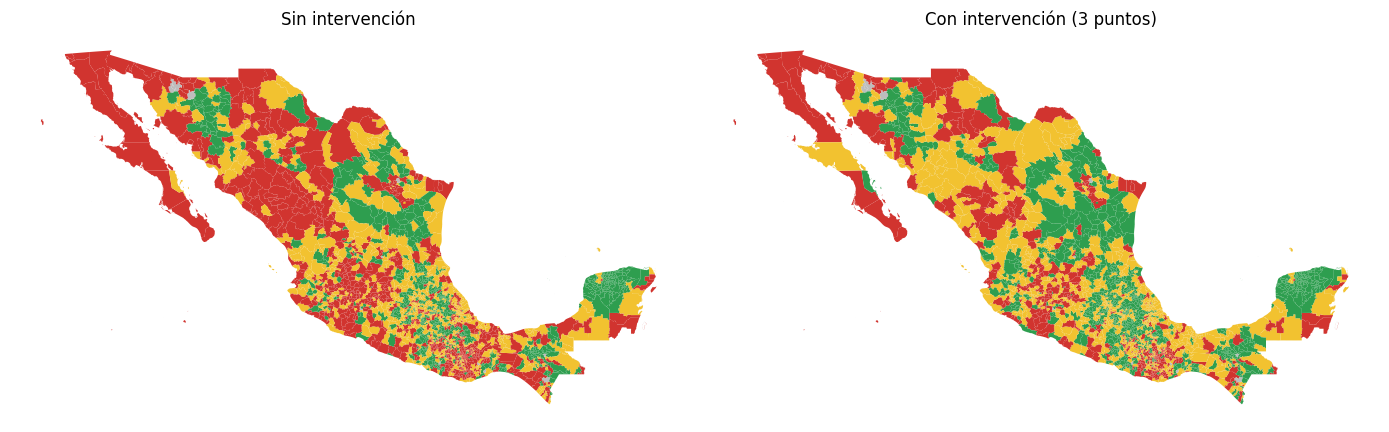

In [9]:
colores = {"Verde": "#2e9e4f", "Amarillo": "#f2c230", "Rojo": "#d1342f", "Sin datos suficientes": "#bdbdbd"}

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
for eje, columna, titulo in [(ejes[0], "SEMAFORO_SIN", "Sin intervención"), (ejes[1], "SEMAFORO_CON_3", "Con intervención (3 puntos)")]:
    for g, color in zip(geometrias, datos[columna].map(colores)):
        for parte in getattr(g, "geoms", [g]):
            eje.fill(*parte.exterior.xy, color=color, linewidth=0)
    eje.set_title(titulo)
    eje.set_aspect("equal")
    eje.axis("off")
plt.tight_layout()
plt.show()